# 03 · Change and compare

**Ask which responses depend on the weight assignment, and report the answer you obtain.**

We compare the same **14-neuron, 22-edge teaching fixture** under its original source weights, one fixed shuffle of those weights, and zero applied input. Each condition begins from the same zero state, with the same model parameters and inspection pools. No Minecraft body, learned controller, or measured biological trial participates.

Setup: [research quickstart](../docs/RESEARCH_QUICKSTART.md). [Current model card](../docs/MODEL_CARD.md).

In [1]:
import os
import sys
from pathlib import Path

# Works when launched from the project root or this notebooks/ directory.
ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file()
        and (path / "research/example-v1/manifest.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the NeuroCraft Fly source directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATASET = ROOT / "research/example-v1"
FIGURES = Path(
    os.environ.get("NEUROCRAFT_RESEARCH_OUTPUT", str(ROOT / "artifacts/research-notebooks/figures"))
)

In [2]:
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from scripts.research_example import ABS_TOL, REL_TOL, load_dataset, simulate, verify
from scripts.research_figures import export_figure, plot_comparison


def show_table(headers, rows):
    def clean(value):
        return str(value).replace("|", " / ").replace("\n", " ")

    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines.extend("| " + " | ".join(clean(value) for value in row) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

## Load the complete comparison

`verify` checks the stored dataset and replays the reference experiment. Every condition is retained, including a control that still responds. We do not select the shuffle based on whether it produces an appealing result.

The notebooks use **numerical replay** with absolute tolerance `1e-12` and relative tolerance `1e-10` (`math.isclose` semantics), allowing small platform/libm differences only in declared floating-point values. Source IDs, configuration, code hashes, schemas, and the stored payload hashes remain exact. A failed check stops the notebook. After successful verification, `load_dataset(..., replay=False)` reads the verified tables without running the experiment a second time.

For the stricter same-platform check, run `uv run --locked python scripts/research_example.py verify`: the CLI defaults to **byte-exact replay**. Numerical replay and byte-exact replay are different checks; passing one is not a claim that the other passed.

In [3]:
report = verify(DATASET, tolerant=True)
example = load_dataset(DATASET, replay=False)
tables = example["tables"]
summary = example["summary"]
conditions = ("original", "shuffled_weights", "no_input")
assert set(summary["conditions"]) == set(conditions)
show_table(
    ["Condition", "Connection assignment", "Applied input"],
    [
        ["original", "Original endpoints and raw counts; modeled signs", "Both prescribed pulses"],
        [
            "shuffled_weights",
            "Same endpoints; raw counts permuted with seed 7",
            "Both prescribed pulses",
        ],
        ["no_input", "Original assignment", "All zero; requested schedule still recorded"],
    ],
)
print("Verification:", report["mode"])
print(f"Replay tolerances: absolute={ABS_TOL:g}, relative={REL_TOL:g}; identities remain exact.")

| Condition | Connection assignment | Applied input |
| --- | --- | --- |
| original | Original endpoints and raw counts; modeled signs | Both prescribed pulses |
| shuffled_weights | Same endpoints; raw counts permuted with seed 7 | Both prescribed pulses |
| no_input | Original assignment | All zero; requested schedule still recorded |

Verification: numerical_replay
Replay tolerances: absolute=1e-12, relative=1e-10; identities remain exact.


## Check what the intervention holds fixed

The shuffle is a **weight permutation, not rewiring**. It preserves source endpoints, the global multiset of raw counts, modeled signs and delays. It does not preserve incoming count totals or normalized weight distributions: incoming normalization is recomputed after the permutation.

The no-input condition records the same requested pulses but applies zero drive. These executable checks make that distinction explicit.

In [4]:
edges = {
    condition: [row for row in tables["edges"] if row["condition"] == condition]
    for condition in conditions
}
fixed_fields = ("edge_index", "body_pre", "body_post", "assigned_sign", "delay_steps")
original_fixed = [tuple(row[field] for field in fixed_fields) for row in edges["original"]]
for condition in conditions:
    assert [
        tuple(row[field] for field in fixed_fields) for row in edges[condition]
    ] == original_fixed
assert sorted(int(row["overlay_count"]) for row in edges["original"]) == sorted(
    int(row["overlay_count"]) for row in edges["shuffled_weights"]
)
assert any(
    left["overlay_count"] != right["overlay_count"]
    for left, right in zip(edges["original"], edges["shuffled_weights"], strict=True)
)
inputs = {
    condition: [row for row in tables["inputs"] if row["condition"] == condition]
    for condition in conditions
}
requested = [row["requested_drive"] for row in inputs["original"]]
assert all(
    [row["requested_drive"] for row in inputs[condition]] == requested for condition in conditions
)
assert [row["applied_drive"] for row in inputs["original"]] == [
    row["applied_drive"] for row in inputs["shuffled_weights"]
]
assert all(float(row["applied_drive"]) == 0.0 for row in inputs["no_input"])
print(
    "Verified: matched endpoints, signs, delays and requested schedule; "
    "shuffled count multiset preserved."
)
print("Verified: identical applied pulses for original/shuffled; zero applied drive for no input.")

Verified: matched endpoints, signs, delays and requested schedule; shuffled count multiset preserved.
Verified: identical applied pulses for original/shuffled; zero applied drive for no input.


## Compare downstream activity

All curves show every committed sample. Colors and line styles distinguish the conditions. The left and right panels share the activity scale within each row. A retained shuffled response is part of the result; it is not hidden or called a failure.

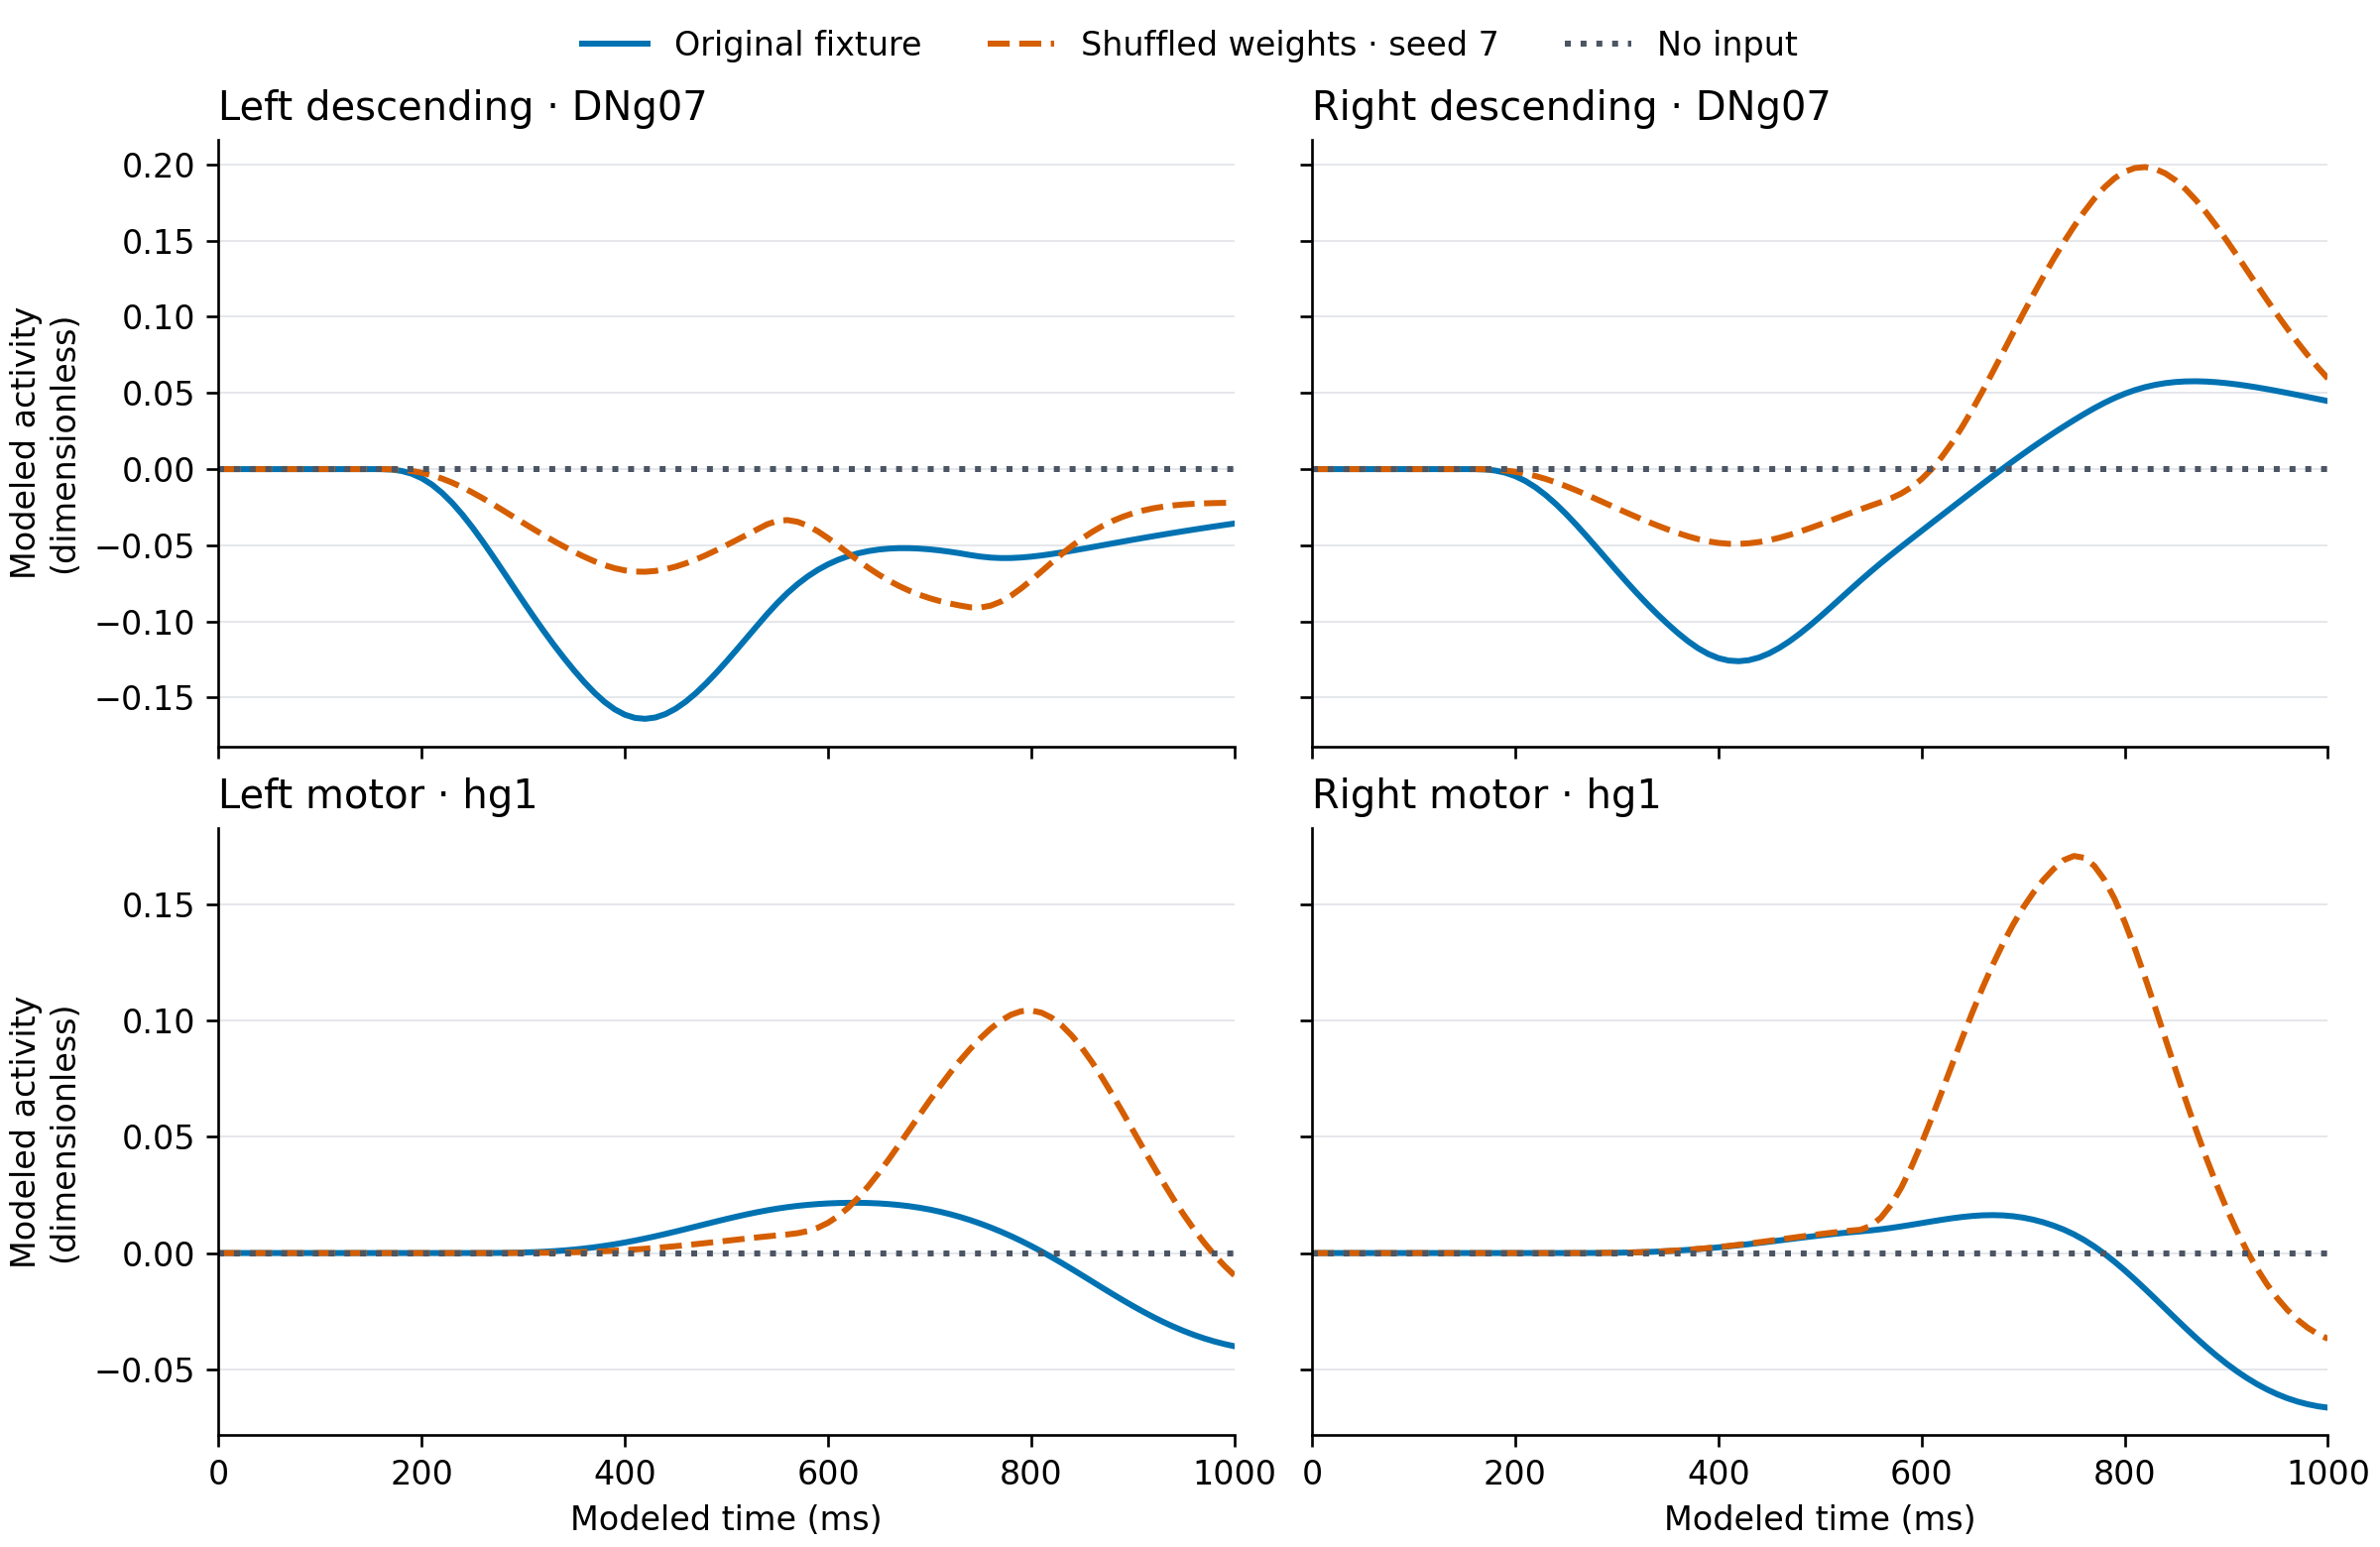

Saved 03_matched_conditions.svg and .png to the configured figure directory.


In [5]:
figure = plot_comparison(tables["readouts"], shuffle_seed=7)
_, png_path = export_figure(figure, FIGURES / "03_matched_conditions")
display(Image(filename=str(png_path)))
plt.close(figure)
print("Saved 03_matched_conditions.svg and .png to the configured figure directory.")

## Calculate the differences directly

For each downstream inspection pool, compare peak absolute activity and the largest pointwise original-versus-shuffled difference over the 101 committed samples. No ratio to the zero-input baseline is used; dividing by zero would manufacture an impressive-looking number.

We derive the differences from the CSV time series and cross-check the stored summary. These values describe this deterministic model experiment, not behavioral performance or biological variability.

In [6]:
downstream_pools = ("DNg07_L", "DNg07_R", "hg1_motor_L", "hg1_motor_R")
measurements = []
for pool in downstream_pools:
    values = {
        condition: [
            float(row["mean_activity"])
            for row in tables["readouts"]
            if row["condition"] == condition and row["pool"] == pool
        ]
        for condition in conditions
    }
    assert all(len(series) == 101 for series in values.values())
    peaks = {condition: max(abs(value) for value in series) for condition, series in values.items()}
    difference = max(
        abs(left - right)
        for left, right in zip(values["original"], values["shuffled_weights"], strict=True)
    )
    assert difference == summary["comparison"][pool]["original_shuffled_max_abs_difference"]
    assert peaks["no_input"] == 0.0
    measurements.append(
        [
            pool,
            f"{peaks['original']:.6f}",
            f"{peaks['shuffled_weights']:.6f}",
            f"{difference:.6f}",
            f"{peaks['no_input']:.6f}",
        ]
    )
show_table(
    ["Pool", "Original peak |a|", "Shuffled peak |a|", "Max pointwise |Δa|", "No-input peak |a|"],
    measurements,
)
retained = sum(
    summary["comparison"][pool]["shuffled_response_retained"] for pool in downstream_pools
)
print(f"Seed 7 retains a nonzero response in {retained}/{len(downstream_pools)} downstream pools.")

| Pool | Original peak |a| | Shuffled peak |a| | Max pointwise |Δa| | No-input peak |a| |
| --- | --- | --- | --- | --- |
| DNg07_L | 0.163930 | 0.090866 | 0.096549 | 0.000000 |
| DNg07_R | 0.126128 | 0.198305 | 0.145829 | 0.000000 |
| hg1_motor_L | 0.040049 | 0.104218 | 0.102887 | 0.000000 |
| hg1_motor_R | 0.066449 | 0.170625 | 0.164219 | 0.000000 |

Seed 7 retains a nonzero response in 4/4 downstream pools.


## Try another declared shuffle

Change the seed, then rerun. This exploratory result does not overwrite `example-v1`. The seed must be chosen before examining its response if you want to avoid selecting a convenient outcome. A single additional shuffle still does not estimate a null distribution.

In [7]:
exploratory_seed = 11
exploratory = simulate(shuffle_seed=exploratory_seed)
show_table(
    ["Pool", "Reference seed 7 peak |a|", f"Exploratory seed {exploratory_seed} peak |a|"],
    [
        [
            pool,
            f"{summary['conditions']['shuffled_weights'][pool]['peak_abs_activity']:.6f}",
            f"{exploratory['summary']['conditions']['shuffled_weights'][pool]['peak_abs_activity']:.6f}",
        ]
        for pool in downstream_pools
    ],
)

| Pool | Reference seed 7 peak |a| | Exploratory seed 11 peak |a| |
| --- | --- | --- |
| DNg07_L | 0.090866 | 0.078493 |
| DNg07_R | 0.198305 | 0.182728 |
| hg1_motor_L | 0.104218 | 0.114839 |
| hg1_motor_R | 0.170625 | 0.223209 |

## What these controls establish

The no-input result tests dependence on applied input from the declared zero state. The weight shuffle tests sensitivity to one weight assignment while preserving graph support. Either original or shuffled responses can remain nonzero; a nonzero difference alone does not establish an advantage for the original network.

To make a stronger ML experiment, define a task and metric before testing, keep the inputs and surrounding controller matched, and compare several seeds with suitable direct and smaller-network baselines. To investigate biological mechanisms, also justify the selected populations, sign and delay assumptions, stimulus mapping, and relevant experimental observations. These notebooks supply neither of those stronger validations.

**Useful next exercises:** inspect which shuffled edges donated their counts using `overlay_source_edge_index`; compare the same prespecified set of seeds; vary recurrent gain while holding the input fixed; or propose a targeted population intervention with an explicit prediction. Record every tested condition, including unchanged responses.

Return to the [research quickstart](../docs/RESEARCH_QUICKSTART.md) for regeneration commands, full-network acquisition, and the separate live Minecraft experiments. The historical 128-neuron fixture readout result and escape-pathway measurements are explained in the [current model card](../docs/MODEL_CARD.md); this fixture run does not reproduce or replace those measurements.